# Trực quan hóa Thực nghiệm các Kỹ thuật SAT Encoding cho N-Queens (Solver: Glucose4)

- **Mục tiêu:** So sánh 5 phương pháp mã hóa At-Most-One (AMO): **Binomial**, **Sequential Counter**, **Binary**, **Commander**, và **2-Product**.
- **Không gian khảo sát:** 15 mốc kích thước bàn cờ: $N \in [4, 8, 16, 25, 36, 49, 64, 81, 100, 125, 216, 343, 512, 729, 1000]$.
- **Chỉ số đánh giá:** Số mệnh đề CNF (Clauses), Số lượng biến phụ (Auxiliary Variables), và Tổng thời gian thực thi (Total Time).


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Thiết lập phong cách hiển thị biểu đồ
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 13,
    'lines.linewidth': 2,
    'lines.markersize': 7,
})

ENCODING_COLORS = {
    'binomial': '#d62728',    # Đỏ
    'sequential': '#1f77b4',  # Xanh dương
    'binary': '#ff7f0e',      # Cam
    'commander': '#2ca02c',   # Xanh lá
    'product': '#9467bd',     # Tím
}

ENCODING_LABELS = {
    'binomial': 'Binomial (Pairwise)',
    'sequential': 'Sequential Counter',
    'binary': 'Binary (Bitwise)',
    'commander': 'Commander (g=3)',
    'product': '2-Product',
}

ENCODING_MARKERS = {
    'binomial': 'o',      # Tròn
    'sequential': 's',    # Vuông
    'binary': '^',        # Tam giác lên
    'commander': 'D',     # Kim cương
    'product': 'v',       # Tam giác xuống
}

print("[✓] Khởi tạo môi trường trực quan hóa thành công! Solver: Glucose4")


[✓] Khởi tạo môi trường trực quan hóa thành công! Solver: Glucose4


In [2]:
# Tải dữ liệu thực nghiệm từ results/data/encoding.csv
data_path = Path('../data/encoding.csv')
df = pd.read_csv(data_path)

print(f"Tổng số bản ghi thực nghiệm: {len(df)}")
print(f"SAT Solver: {df['solver'].unique().tolist()}")
print(f"Các giá trị N khảo sát: {sorted(df['n'].unique().tolist())}")
print(f"Các phương pháp encoding: {df['encoding'].unique().tolist()}")
display(df.head(10))


Tổng số bản ghi thực nghiệm: 75
SAT Solver: ['glucose4']
Các giá trị N khảo sát: [4, 8, 16, 25, 36, 49, 64, 81, 100, 125, 216, 343, 512, 729, 1000]
Các phương pháp encoding: ['binomial', 'sequential', 'binary', 'commander', 'product']


,n,encoding,solver,variables,aux_vars,clauses,gen_time,solve_time,total_time,sat,status
0,4,binomial,glucose4,16,0,84,0.000031,0.000361,0.000393,True,SAT
1,4,sequential,glucose4,58,42,116,0.000033,0.000285,0.000318,True,SAT
2,4,binary,glucose4,48,32,120,0.000065,0.000339,0.000405,True,SAT
3,4,commander,glucose4,26,10,104,0.000040,0.000171,0.000211,True,SAT
4,4,product,glucose4,56,40,124,0.000059,0.000281,0.000340,True,SAT
5,8,binomial,glucose4,64,0,744,0.000171,0.000622,0.000792,True,SAT
6,8,sequential,glucose4,274,210,604,0.000089,0.000684,0.000773,True,SAT
7,8,binary,glucose4,174,110,728,0.000144,0.000603,0.000746,True,SAT
8,8,commander,glucose4,146,82,618,0.000122,0.000686,0.000808,True,SAT
9,8,product,glucose4,252,188,668,0.000109,0.000614,0.000723,True,SAT


## 1. Số lượng Mệnh đề CNF (Clauses)


encoding,binary,binomial,commander,product,sequential
n,,,,,
4,120.0,84.0,104.0,124.0,116.0
8,728.0,744.0,618.0,668.0,604.0
16,3928.0,6352.0,3052.0,3236.0,2732.0
25,11806.0,24850.0,7810.0,7894.0,6962.0
36,28320.0,75252.0,16904.0,15548.0,14772.0
49,54866.0,191394.0,32014.0,27998.0,27746.0
64,95576.0,428864.0,55022.0,45876.0,47756.0
81,172694.0,872802.0,88778.0,70966.0,76962.0
100,269024.0,1646900.0,136560.0,108596.0,117812.0


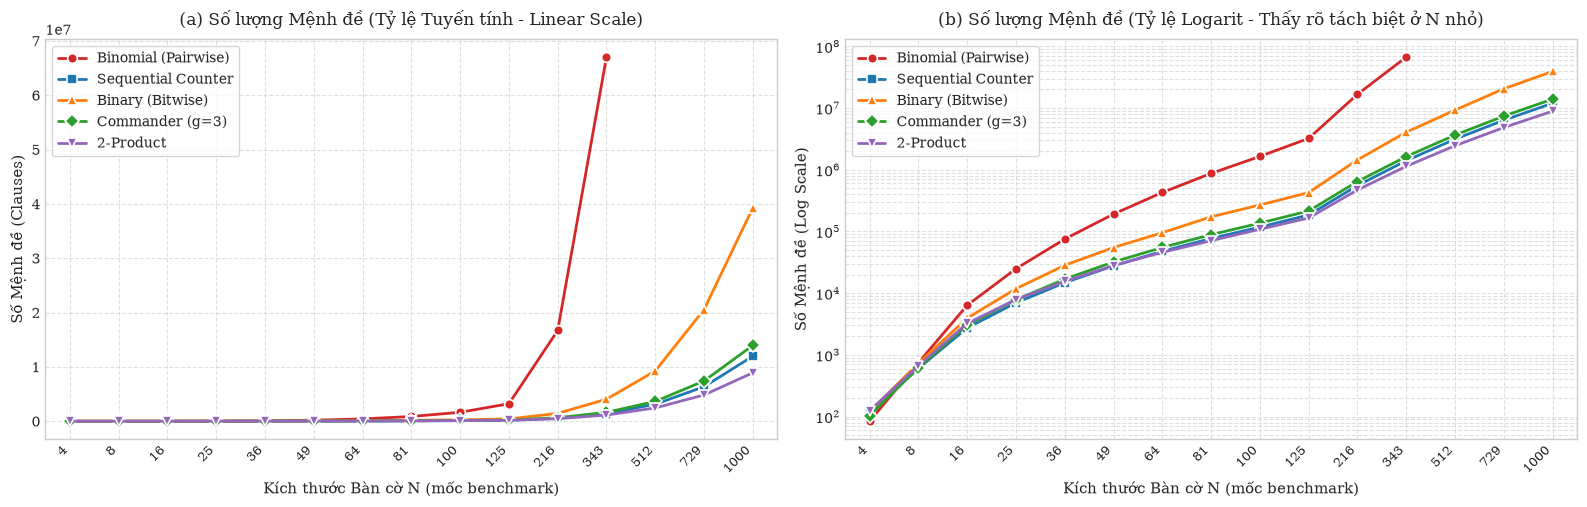

In [3]:
# 1. Bảng Pivot Số lượng Mệnh đề theo N
pivot_clauses = df[df['clauses'] > 0].pivot(index='n', columns='encoding', values='clauses')
display(pivot_clauses)

# 2. Vẽ biểu đồ Clauses vs N (2 Subplots: Linear Scale & Log Scale)
n_list = [4, 8, 16, 25, 36, 49, 64, 81, 100, 125, 216, 343, 512, 729, 1000]
x_map = {n: i for i, n in enumerate(n_list)}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.2))

for enc in ['binomial', 'sequential', 'binary', 'commander', 'product']:
    data_enc = df[(df['encoding'] == enc) & (df['clauses'] > 0)].sort_values('n')
    lbl = ENCODING_LABELS.get(enc, enc)
    color = ENCODING_COLORS.get(enc, None)
    marker = ENCODING_MARKERS.get(enc, 'o')
    if not data_enc.empty:
        xs = [x_map[n] for n in data_enc['n']]
        # Subplot 1: Linear Scale
        ax1.plot(xs, data_enc['clauses'], marker=marker, markersize=7, markeredgecolor='white', markeredgewidth=1.2, label=lbl, color=color, linewidth=2)
        # Subplot 2: Log Scale
        ax2.plot(xs, data_enc['clauses'], marker=marker, markersize=7, markeredgecolor='white', markeredgewidth=1.2, label=lbl, color=color, linewidth=2)

# Thiết lập Subplot 1: Linear
ax1.set_title('(a) Số lượng Mệnh đề (Tỷ lệ Tuyến tính - Linear Scale)', fontsize=12, pad=10)
ax1.set_xlabel('Kích thước Bàn cờ N (mốc benchmark)', fontsize=11)
ax1.set_ylabel('Số Mệnh đề (Clauses)', fontsize=11)
ax1.set_xticks(range(len(n_list)))
ax1.set_xticklabels(n_list, rotation=45, ha='right', fontsize=9)
ax1.set_xlim(-0.5, len(n_list) - 0.5)
ax1.legend(frameon=True, loc='upper left', fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.6)

# Thiết lập Subplot 2: Log
ax2.set_title('(b) Số lượng Mệnh đề (Tỷ lệ Logarit - Thấy rõ tách biệt ở N nhỏ)', fontsize=12, pad=10)
ax2.set_xlabel('Kích thước Bàn cờ N (mốc benchmark)', fontsize=11)
ax2.set_ylabel('Số Mệnh đề (Log Scale)', fontsize=11)
ax2.set_yscale('log')
ax2.set_xticks(range(len(n_list)))
ax2.set_xticklabels(n_list, rotation=45, ha='right', fontsize=9)
ax2.set_xlim(-0.5, len(n_list) - 0.5)
ax2.legend(frameon=True, loc='upper left', fontsize=10)
ax2.grid(True, which='both', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('../figures/encoding_clauses.png', dpi=300, bbox_inches='tight')
plt.show()


## 2. Số lượng Biến phụ (Auxiliary Variables)


encoding,binary,binomial,commander,product,sequential
n,,,,,
4,32.0,0.0,10.0,40.0,42.0
8,110.0,0.0,82.0,188.0,210.0
16,316.0,0.0,426.0,996.0,930.0
25,616.0,0.0,1084.0,2164.0,2352.0
36,1032.0,0.0,2394.0,3692.0,4970.0
49,1500.0,0.0,4608.0,5952.0,9312.0
64,2040.0,0.0,7862.0,8636.0,16002.0
81,2880.0,0.0,12616.0,11916.0,25760.0
100,3678.0,0.0,19502.0,18408.0,39402.0


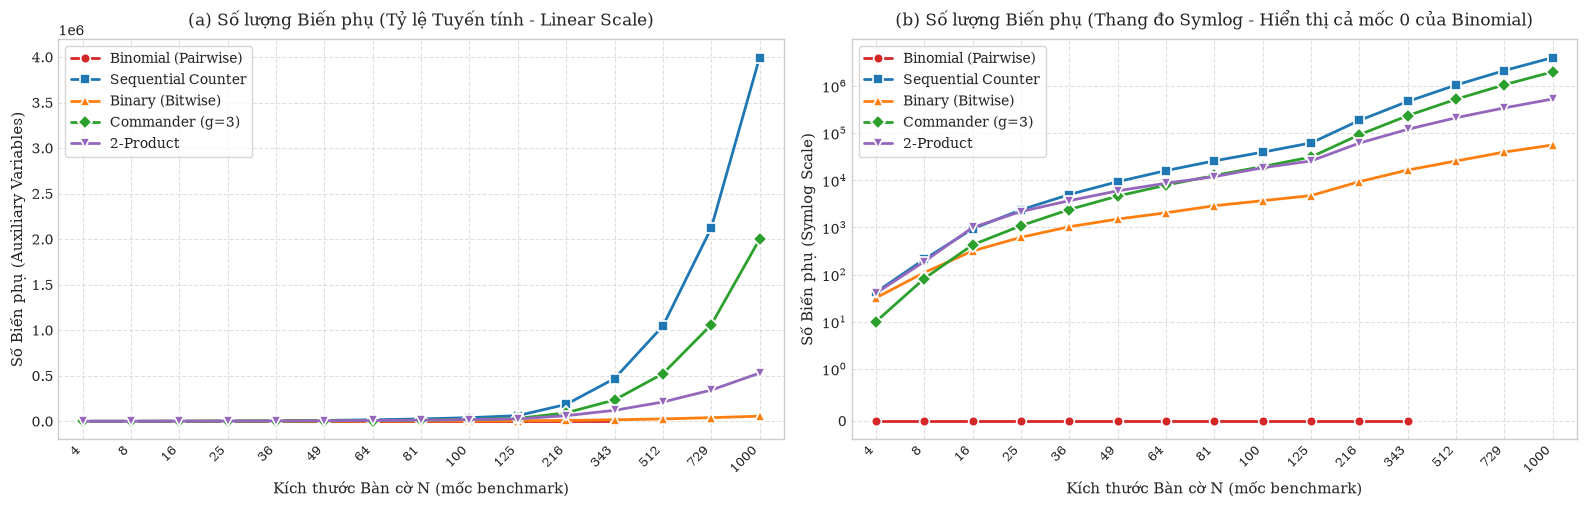

In [4]:
# 1. Bảng Pivot Số lượng Biến phụ (Auxiliary Variables)
pivot_aux = df[df['clauses'] > 0].pivot(index='n', columns='encoding', values='aux_vars')
display(pivot_aux)

# 2. Vẽ biểu đồ Số biến phụ vs N (2 Subplots: Linear Scale & Symlog Scale)
n_list = [4, 8, 16, 25, 36, 49, 64, 81, 100, 125, 216, 343, 512, 729, 1000]
x_map = {n: i for i, n in enumerate(n_list)}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.2))

for enc in ['binomial', 'sequential', 'binary', 'commander', 'product']:
    data_enc = df[(df['encoding'] == enc) & (df['clauses'] > 0)].sort_values('n')
    lbl = ENCODING_LABELS.get(enc, enc)
    color = ENCODING_COLORS.get(enc, None)
    marker = ENCODING_MARKERS.get(enc, 'o')
    if not data_enc.empty:
        xs = [x_map[n] for n in data_enc['n']]
        # Subplot 1: Linear Scale
        ax1.plot(xs, data_enc['aux_vars'], marker=marker, markersize=7, markeredgecolor='white', markeredgewidth=1.2, label=lbl, color=color, linewidth=2)
        # Subplot 2: Symlog Scale
        ax2.plot(xs, data_enc['aux_vars'], marker=marker, markersize=7, markeredgecolor='white', markeredgewidth=1.2, label=lbl, color=color, linewidth=2)

# Thiết lập Subplot 1: Linear
ax1.set_title('(a) Số lượng Biến phụ (Tỷ lệ Tuyến tính - Linear Scale)', fontsize=12, pad=10)
ax1.set_xlabel('Kích thước Bàn cờ N (mốc benchmark)', fontsize=11)
ax1.set_ylabel('Số Biến phụ (Auxiliary Variables)', fontsize=11)
ax1.set_xticks(range(len(n_list)))
ax1.set_xticklabels(n_list, rotation=45, ha='right', fontsize=9)
ax1.set_xlim(-0.5, len(n_list) - 0.5)
ax1.legend(frameon=True, loc='upper left', fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.6)

# Thiết lập Subplot 2: Symlog
ax2.set_title('(b) Số lượng Biến phụ (Thang đo Symlog - Hiển thị cả mốc 0 của Binomial)', fontsize=12, pad=10)
ax2.set_xlabel('Kích thước Bàn cờ N (mốc benchmark)', fontsize=11)
ax2.set_ylabel('Số Biến phụ (Symlog Scale)', fontsize=11)
ax2.set_yscale('symlog', linthresh=1)
ax2.set_xticks(range(len(n_list)))
ax2.set_xticklabels(n_list, rotation=45, ha='right', fontsize=9)
ax2.set_xlim(-0.5, len(n_list) - 0.5)
ax2.legend(frameon=True, loc='upper left', fontsize=10)
ax2.grid(True, which='both', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('../figures/encoding_aux_vars.png', dpi=300, bbox_inches='tight')
plt.show()


## 3. Tổng Thời gian Thực thi (Total Execution Time với Glucose4)

encoding,binary,binomial,commander,product,sequential
n,,,,,
4,0.000405,0.000393,0.000211,0.000340,0.000318
8,0.000746,0.000792,0.000808,0.000723,0.000773
16,0.020928,0.010939,0.017596,0.103921,0.006000
25,0.052895,0.009161,0.175294,0.140775,0.060895
36,0.052506,0.027140,0.042349,7.737431,0.164782
49,0.051161,0.083984,0.837507,10.474239,1.145701
64,0.136394,0.181400,0.067207,12.070088,1.652627
81,0.117590,0.358687,0.270753,15.557980,24.019350
100,0.147383,0.688519,0.164740,15.328598,46.524576


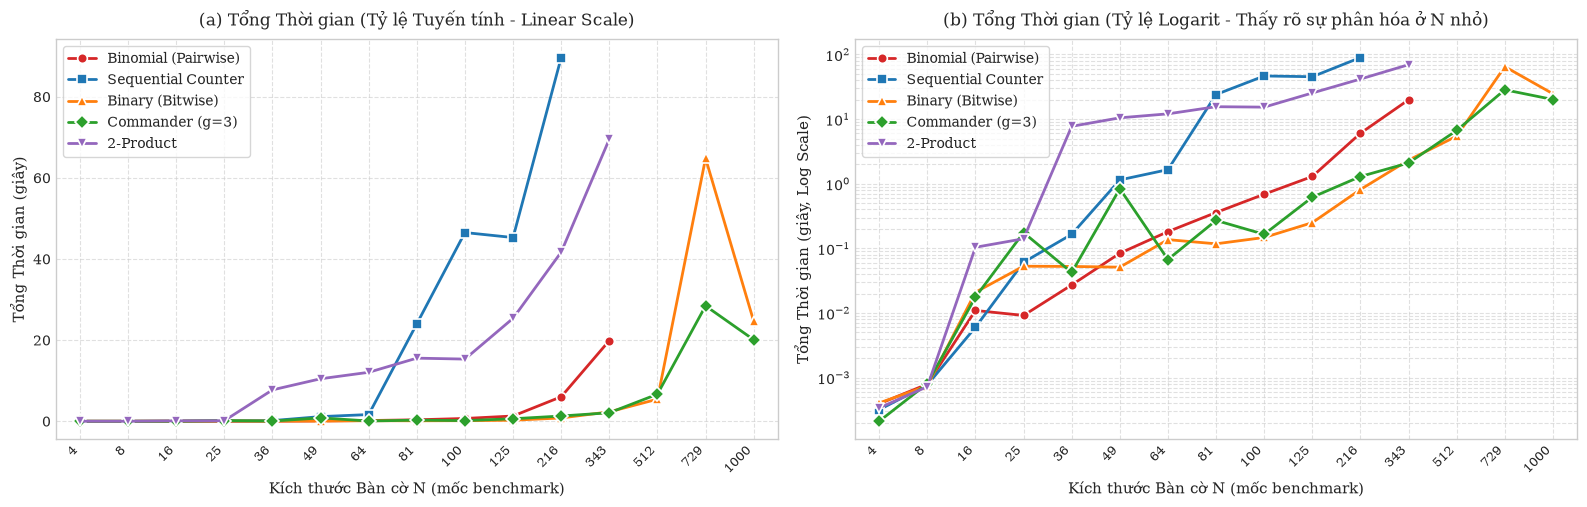

In [5]:
# 1. Bảng Pivot Tổng Thời gian Thực thi (giây)
pivot_time = df[df['status'] == 'SAT'].pivot(index='n', columns='encoding', values='total_time')
display(pivot_time)

# 2. Vẽ biểu đồ Total Execution Time vs N (2 Subplots: Linear Scale & Log Scale)
n_list = [4, 8, 16, 25, 36, 49, 64, 81, 100, 125, 216, 343, 512, 729, 1000]
x_map = {n: i for i, n in enumerate(n_list)}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.2))

for enc in ['binomial', 'sequential', 'binary', 'commander', 'product']:
    data_enc = df[(df['encoding'] == enc) & (df['status'] == 'SAT')].sort_values('n')
    lbl = ENCODING_LABELS.get(enc, enc)
    color = ENCODING_COLORS.get(enc, None)
    marker = ENCODING_MARKERS.get(enc, 'o')
    if not data_enc.empty:
        xs = [x_map[n] for n in data_enc['n']]
        # Subplot 1: Linear Scale
        ax1.plot(xs, data_enc['total_time'], marker=marker, markersize=7, markeredgecolor='white', markeredgewidth=1.2, label=lbl, color=color, linewidth=2)
        # Subplot 2: Log Scale
        ax2.plot(xs, data_enc['total_time'], marker=marker, markersize=7, markeredgecolor='white', markeredgewidth=1.2, label=lbl, color=color, linewidth=2)

# Thiết lập Subplot 1: Linear
ax1.set_title('(a) Tổng Thời gian (Tỷ lệ Tuyến tính - Linear Scale)', fontsize=12, pad=10)
ax1.set_xlabel('Kích thước Bàn cờ N (mốc benchmark)', fontsize=11)
ax1.set_ylabel('Tổng Thời gian (giây)', fontsize=11)
ax1.set_xticks(range(len(n_list)))
ax1.set_xticklabels(n_list, rotation=45, ha='right', fontsize=9)
ax1.set_xlim(-0.5, len(n_list) - 0.5)
ax1.legend(frameon=True, loc='upper left', fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.6)

# Thiết lập Subplot 2: Log
ax2.set_title('(b) Tổng Thời gian (Tỷ lệ Logarit - Thấy rõ sự phân hóa ở N nhỏ)', fontsize=12, pad=10)
ax2.set_xlabel('Kích thước Bàn cờ N (mốc benchmark)', fontsize=11)
ax2.set_ylabel('Tổng Thời gian (giây, Log Scale)', fontsize=11)
ax2.set_yscale('log')
ax2.set_xticks(range(len(n_list)))
ax2.set_xticklabels(n_list, rotation=45, ha='right', fontsize=9)
ax2.set_xlim(-0.5, len(n_list) - 0.5)
ax2.legend(frameon=True, loc='upper left', fontsize=10)
ax2.grid(True, which='both', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('../figures/encoding_total_time.png', dpi=300, bbox_inches='tight')
plt.show()


## 4. Tóm tắt Kết luận Chính

1. **Binary (Bitwise) - Tối ưu nhất cho SAT Solving quy mô lớn:**
   - Số biến phụ tối thiểu ($55.8\text{K}$ tại $N = 1000$) giúp Glucose4 giải quyết dễ dàng mà không bị bùng nổ phân nhánh.
2. **Commander Variable:**
   - Cân bằng hoàn hảo giữa biến phụ và mệnh đề, giải nhanh nhất ở phân khúc $N \le 200$ và giải ổn định tới $N = 1000$.
3. **Sequential Counter & 2-Product:**
   - Số lượng mệnh đề sinh ra rất ít, nhưng lượng biến phụ cao gây áp lực bộ nhớ và heuristic LBD dẫn tới timeout ở $N \ge 343$ (Sequential) và $N \ge 512$ (Product).
4. **Binomial (Pairwise):**
   - Không có biến phụ, giải rất nhanh ở ma trận nhỏ ($N \le 20$), sinh tới $67.0\text{M}$ mệnh đề tại $N = 343$ và vượt quá bộ nhớ RAM ở $N \ge 512$.
